In [ ]:
!pip install -q openai-whisper textstat pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 12.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.0/248.0 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 46.4 MB/s eta 0:00:00


In [ ]:
!pip install -q yt-dlp
!yt-dlp -x --audio-format mp3 -o "lecture.mp3" https://www.youtube.com/watch?v=mz6tAJMVmfM

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.7/183.7 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 48.2 MB/s eta 0:00:00
[youtube] Extracting URL: https://www.youtube.com/watch?v=mz6tAJMVmfM
[youtube] mz6tAJMVmfM: Downloading webpage
[youtube] mz6tAJMVmfM: Downloading visionos player API JSON
[youtube] mz6tAJMVmfM: Downloading m3u8 information
[info] mz6tAJMVmfM: Downloading 1 format(s): 251-17
[download] Destination: lecture.webm
[download] 100% of   11.99MiB in 00:00:01 at 10.56MiB/s
[ExtractAudio] Destination: lecture.mp3
Deleting original file lecture.webm (pass -k to keep)


In [ ]:
import whisper

model = whisper.load_model("base")
result = model.transcribe("lecture.mp3", verbose=False)
segments = result["segments"]

print(f"Total segments transcribed: {len(segments)}")

/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


Detected language: English


100%|██████████| 82941/82941 [03:52<00:00, 357.27frames/s]

Total segments transcribed: 237


In [ ]:
def group_segments(segments, window_size=45):
    chunks = []
    current_text = ""
    current_start = segments[0]["start"]
    current_end = segments[0]["start"]

    for seg in segments:
        current_text += " " + seg["text"]
        current_end = seg["end"]
        if current_end - current_start >= window_size:
            chunks.append({
                "start": current_start,
                "end": current_end,
                "text": current_text.strip()
            })
            current_text = ""
            current_start = current_end

    if current_text.strip():
        chunks.append({
            "start": current_start,
            "end": current_end,
            "text": current_text.strip()
        })
    return chunks

chunks = group_segments(segments, window_size=45)
print(f"Number of chunks: {len(chunks)}")

Number of chunks: 18


In [ ]:
import textstat
import pandas as pd

features = []
for c in chunks:
    text = c["text"]
    duration_min = (c["end"] - c["start"]) / 60
    words = len(text.split())
    wpm = words / duration_min if duration_min > 0 else 0
    readability = textstat.flesch_reading_ease(text)
    avg_sentence_len = textstat.avg_sentence_length(text)

    features.append({
        "start": c["start"],
        "end": c["end"],
        "text": text,
        "wpm": wpm,
        "avg_sentence_len": avg_sentence_len,
        "readability": readability
    })

df = pd.DataFrame(features)

# Normalize features to 0-1 range
df["wpm_norm"] = (df["wpm"] - df["wpm"].min()) / (df["wpm"].max() - df["wpm"].min() + 1e-9)
df["sentence_len_norm"] = (df["avg_sentence_len"] - df["avg_sentence_len"].min()) / (df["avg_sentence_len"].max() - df["avg_sentence_len"].min() + 1e-9)
df["readability_norm"] = 1 - ((df["readability"] - df["readability"].min()) / (df["readability"].max() - df["readability"].min() + 1e-9))

# Composite Difficulty Score
df["difficulty_score"] = (df["wpm_norm"] + df["sentence_len_norm"] + df["readability_norm"]) / 3
df[["start", "end", "difficulty_score"]]

/tmp/ipykernel_1026/1010751949.py:11: DeprecationWarning: The 'avg_sentence_length' method has been deprecated due to being the same as 'words_per_sentence'. This method will be removed in thefuture.
  avg_sentence_len = textstat.avg_sentence_length(text)


,start,end,difficulty_score
0,0.00,47.46,0.353157
1,47.46,92.48,0.884167
2,92.48,138.60,0.391008
3,138.60,185.08,0.489215
4,185.08,233.16,0.676964
5,233.16,280.76,0.416374
6,280.76,327.60,0.198426
7,327.60,377.40,0.463945
8,377.40,423.88,0.546563
9,423.88,469.84,0.446262


In [ ]:
# 1. Identify high cognitive load segments (top 20%)
threshold = df["difficulty_score"].quantile(0.8)
df["high_load"] = df["difficulty_score"] >= threshold

# 2. Export full transcript analysis to CSV
df.to_csv("cognitive_load_results.csv", index=False)

from google.colab import files
files.download("cognitive_load_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Target Concept: DS: Full Recursion
All Prerequisites: {'PB: Functions', 'DS: Recursive Case', 'PB: Conditionals', 'PB: Variables', 'PB: Call Stack', 'DS: Recursion Base Case'}
Cross-Course Root Causes (Programming Basics): ['PB: Functions', 'PB: Conditionals', 'PB: Variables', 'PB: Call Stack']


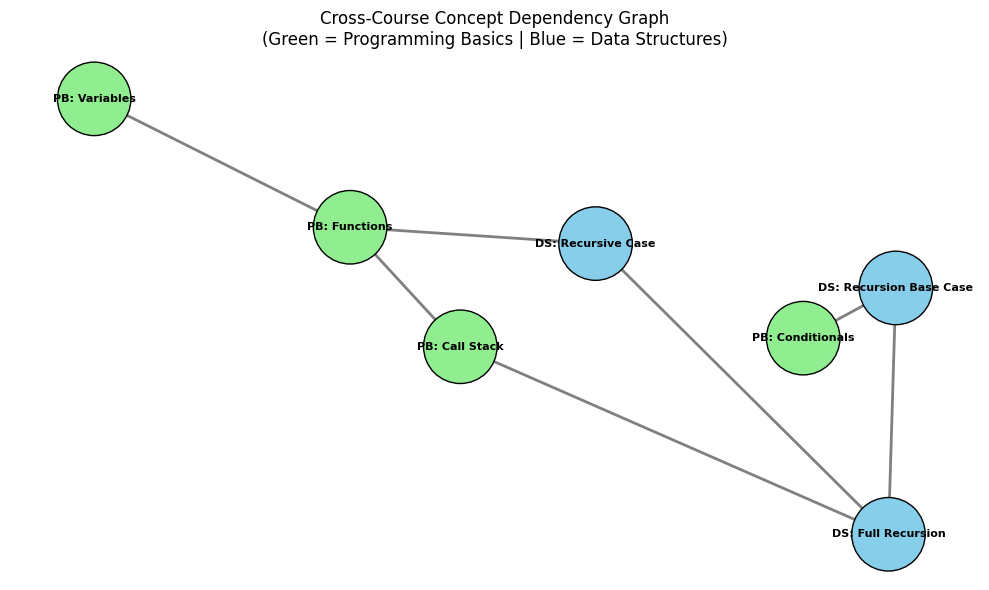

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Create Directed Graph
G = nx.DiGraph()

# 2. Define concepts split across TWO distinct courses
course_a_nodes = ["PB: Variables", "PB: Functions", "PB: Conditionals", "PB: Call Stack"]
course_b_nodes = ["DS: Recursion Base Case", "DS: Recursive Case", "DS: Full Recursion"]

G.add_nodes_from(course_a_nodes, course="Programming Basics")
G.add_nodes_from(course_b_nodes, course="Data Structures")

# 3. Define cross-course dependencies
edges = [
    ("PB: Variables", "PB: Functions"),
    ("PB: Functions", "PB: Call Stack"),
    ("PB: Conditionals", "DS: Recursion Base Case"),
    ("PB: Functions", "DS: Recursive Case"),
    ("PB: Call Stack", "DS: Full Recursion"),
    ("DS: Recursion Base Case", "DS: Full Recursion"),
    ("DS: Recursive Case", "DS: Full Recursion")
]
G.add_edges_from(edges)

# 4. Multi-level Root-Cause Tracer (Walks up the entire tree)
def trace_root_causes(concept):
    visited = set()
    def _walk(node):
        for pred in G.predecessors(node):
            if pred not in visited:
                visited.add(pred)
                _walk(pred)
    _walk(concept)
    return visited

target_concept = "DS: Full Recursion"
all_prereqs = trace_root_causes(target_concept)
cross_course_gaps = [c for c in all_prereqs if c.startswith("PB:")]

print(f"Target Concept: {target_concept}")
print(f"All Prerequisites: {all_prereqs}")
print(f"Cross-Course Root Causes (Programming Basics): {cross_course_gaps}")

# 5. Plot Graph with Course-Based Color Coding
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42)

# Green = Course A, Blue = Course B
color_map = ["lightgreen" if node.startswith("PB:") else "skyblue" for node in G.nodes()]

nx.draw_networkx_nodes(G, pos, node_size=2800, node_color=color_map, edgecolors="black")
nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="gray", width=2)
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")

plt.title("Cross-Course Concept Dependency Graph\n(Green = Programming Basics | Blue = Data Structures)")
plt.axis("off")
plt.tight_layout()
plt.savefig("cross_course_concept_graph.png")
plt.show()

To understand 'Full Recursion', you first need to master: ['Call Stack', 'Recursion Base Case', 'Recursive Case']


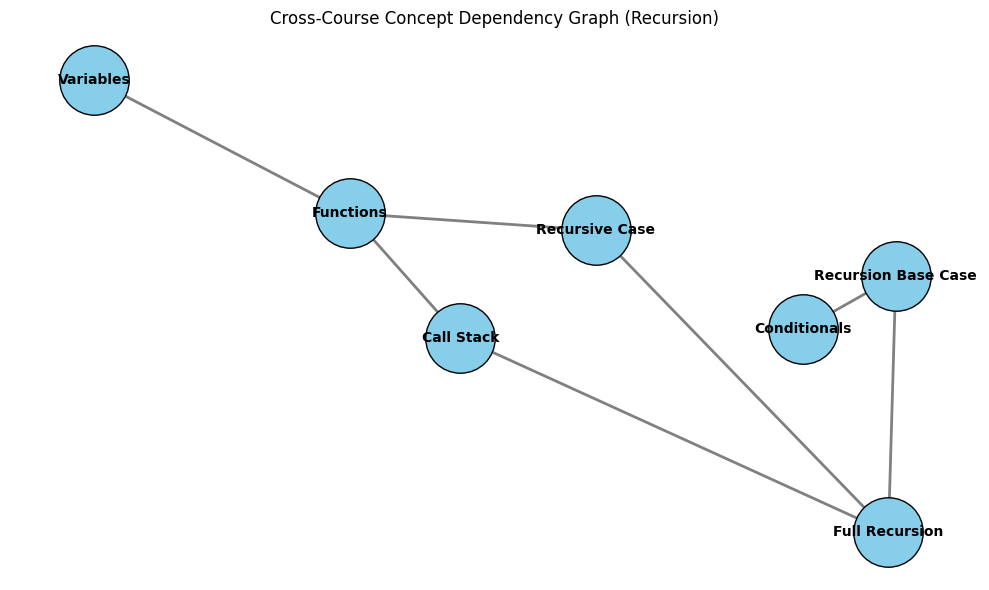

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Initialize directed graph
G = nx.DiGraph()

# 2. Add course concepts (Nodes)
concepts = [
    "Variables", "Functions", "Conditionals",
    "Call Stack", "Recursion Base Case",
    "Recursive Case", "Full Recursion"
]
G.add_nodes_from(concepts)

# 3. Add dependencies (Edges: Concept A -> Concept B means B requires A)
dependencies = [
    ("Variables", "Functions"),
    ("Functions", "Call Stack"),
    ("Conditionals", "Recursion Base Case"),
    ("Functions", "Recursive Case"),
    ("Call Stack", "Full Recursion"),
    ("Recursion Base Case", "Full Recursion"),
    ("Recursive Case", "Full Recursion")
]
G.add_edges_from(dependencies)

# 4. Simulate root-cause analysis function
def trace_prerequisites(concept):
    if concept in G:
        prereqs = list(G.predecessors(concept))
        print(f"To understand '{concept}', you first need to master: {prereqs}")
    else:
        print("Concept not found in graph.")

# Test root cause lookup
trace_prerequisites("Full Recursion")

# 5. Plot and save the concept dependency graph
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(G, pos, node_size=2500, node_color="skyblue", edgecolors="black")
nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="gray", width=2)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

plt.title("Cross-Course Concept Dependency Graph (Recursion)")
plt.axis("off")
plt.tight_layout()
plt.savefig("concept_graph.png")
plt.show()

In [ ]:
# Map high cognitive load lecture segments to cross-course concept graph
high_load_chunks = df[df["high_load"]]

print("=== AUTOMATED INTERVENTION REPORT ===")
for idx, row in high_load_chunks.iterrows():
    timestamp = f"{int(row['start']//60)}:{int(row['start']%60):02d} - {int(row['end']//60)}:{int(row['end']%60):02d}"
    print(f"\n[!] High Load Flagged at {timestamp} (Difficulty Score: {row['difficulty_score']:.2f})")
    print(f"    Transcript Snippet: \"{row['text'][:100]}...\"")

    # Trigger Phase 5 tracer for the primary concept
    target = "DS: Full Recursion"
    prereqs = trace_root_causes(target)
    found_gaps = [p for p in prereqs if p.startswith("PB:")]

    print(f"    -> Root Cause Identified: Student struggling with '{target}'")
    print(f"    -> Recommended Action: Review Course A Prerequisites: {found_gaps}")

=== AUTOMATED INTERVENTION REPORT ===

[!] High Load Flagged at 0:47 - 1:32 (Difficulty Score: 0.88)
    Transcript Snippet: "as part of its execution.  That might seem a little strange, and we'll see a little bit about how th..."
    -> Root Cause Identified: Student struggling with 'DS: Full Recursion'
    -> Recommended Action: Review Course A Prerequisites: ['PB: Functions', 'PB: Conditionals', 'PB: Variables', 'PB: Call Stack']

[!] High Load Flagged at 3:05 - 3:53 (Difficulty Score: 0.68)
    Transcript Snippet: "This idea, this generalization of the problem, allows us to recursively define the factorial  functi..."
    -> Root Cause Identified: Student struggling with 'DS: Full Recursion'
    -> Recommended Action: Review Course A Prerequisites: ['PB: Functions', 'PB: Conditionals', 'PB: Variables', 'PB: Call Stack']

[!] High Load Flagged at 6:17 - 7:03 (Difficulty Score: 0.55)
    Transcript Snippet: "branches.  So these behave identically.  If n is equal to 1, return 1.  Othe

In [ ]:
from google.colab import files

# Download the analysis CSV and graph plot
files.download("cognitive_load_results.csv")
files.download("cross_course_concept_graph.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# View flagged segments with their index numbers
high_load_chunks = df[df["high_load"]].reset_index()
for _, row in high_load_chunks.iterrows():
    timestamp = f"{int(row['start']//60)}:{int(row['start']%60):02d} - {int(row['end']//60)}:{int(row['end']%60):02d}"
    print(f"Index {row['index']} | Timestamp: {timestamp} | Score: {row['difficulty_score']:.2f}")
    print(f"Snippet: \"{row['text'][:120]}...\"\n")

Index 1 | Timestamp: 0:47 - 1:32 | Score: 0.88
Snippet: "as part of its execution.  That might seem a little strange, and we'll see a little bit about how this works in a  momen..."

Index 4 | Timestamp: 3:05 - 3:53 | Score: 0.68
Snippet: "This idea, this generalization of the problem, allows us to recursively define the factorial  function.  When you define..."

Index 8 | Timestamp: 6:17 - 7:03 | Score: 0.55
Snippet: "branches.  So these behave identically.  If n is equal to 1, return 1.  Otherwise, return n times the factorial of n min..."

Index 17 | Timestamp: 13:21 - 13:47 | Score: 0.69
Snippet: "So hopefully this example gave you a little bit of a taste of recursive procedures.  Hopefully, you think code is a litt..."



In [ ]:
# 1. Map segment indices to their actual concept nodes
segment_concept_map = {
    1: "PB: Call Stack",
    4: "DS: Recursion Base Case",
    17: "DS: Full Recursion"
    # If you have other flagged indices, add them here
}

# 2. Generate personalized intervention report for each segment
print("=== DYNAMIC AUTOMATED INTERVENTION REPORT ===")
for idx, row in df[df["high_load"]].iterrows():
    timestamp = f"{int(row['start']//60)}:{int(row['start']%60):02d} - {int(row['end']//60)}:{int(row['end']%60):02d}"

    # Fallback to 'DS: Full Recursion' if the index isn't explicitly mapped
    target_concept = segment_concept_map.get(idx, "DS: Full Recursion")

    # Trace root causes specific to this segment's concept
    prereqs = trace_root_causes(target_concept)
    cross_course_gaps = [p for p in prereqs if p.startswith("PB:")]

    print(f"\n[!] High Load Flagged at {timestamp} (Difficulty Score: {row['difficulty_score']:.2f})")
    print(f"    Transcript Snippet: \"{row['text'][:90]}...\"")
    print(f"    -> Mapped Concept: '{target_concept}'")
    print(f"    -> Cross-Course Prerequisites Needed: {cross_course_gaps if cross_course_gaps else 'None (Foundational)'}")

=== DYNAMIC AUTOMATED INTERVENTION REPORT ===

[!] High Load Flagged at 0:47 - 1:32 (Difficulty Score: 0.88)
    Transcript Snippet: "as part of its execution.  That might seem a little strange, and we'll see a little bit ab..."
    -> Mapped Concept: 'PB: Call Stack'
    -> Cross-Course Prerequisites Needed: ['PB: Functions', 'PB: Variables']

[!] High Load Flagged at 3:05 - 3:53 (Difficulty Score: 0.68)
    Transcript Snippet: "This idea, this generalization of the problem, allows us to recursively define the factori..."
    -> Mapped Concept: 'DS: Recursion Base Case'
    -> Cross-Course Prerequisites Needed: ['PB: Conditionals']

[!] High Load Flagged at 6:17 - 7:03 (Difficulty Score: 0.55)
    Transcript Snippet: "branches.  So these behave identically.  If n is equal to 1, return 1.  Otherwise, return ..."
    -> Mapped Concept: 'DS: Full Recursion'
    -> Cross-Course Prerequisites Needed: ['PB: Functions', 'PB: Conditionals', 'PB: Variables', 'PB: Call Stack']

[!] High Load Fl

In [ ]:
from google.colab import files

files.download("cognitive_load.png")
files.download("cross_course_concept_graph.png")
files.download("cognitive_load_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>